# Лабораторная работа 3. Первая свёрточная нейронная сеть
Оспан Әсел Ғалымжанқызы · Казахский национальный университет имени аль-Фараби

Сначала вычислите одну карту признаков вручную и проверьте её через PyTorch.
Затем проследите формы тензоров и обучите классификатор одежды на Fashion-MNIST.
Ячейки содержат полный код. Для второго этапа требуется установленный PyTorch и четыре
файла IDX в gzip или доступ к официальному репозиторию для их загрузки.

## 1. Кросс-корреляция на небольших матрицах
Первый индекс карты обозначает строку, второй — столбец. На базовом примере
$Y_{00}=1\cdot1+2\cdot0+3\cdot(-1)+1\cdot1=-1$.
Выполните ручной расчёт для остальных позиций и сравните со значениями ячеек.

In [1]:
"""Ручная кросс-корреляция и проверка через PyTorch."""

import torch
from torch.nn import functional as F


def example():
    image = [[1, 2, 0, 1], [3, 1, 2, 2], [0, 2, 1, 0], [1, 1, 3, 2]]
    kernel = [[1, 0], [-1, 1]]
    return image, kernel


def two_channel_example():
    image, kernel = example()
    other = [[2, 1, 0, 1], [0, 1, 1, 2], [1, 0, 2, 1], [2, 1, 0, 0]]
    other_kernel = [[0, 1], [1, 0]]
    return [image, other], [kernel, other_kernel], 0.5


def channels_first(values):
    """Превращаем H×W в 1×H×W, C×H×W сохраняем."""
    if not values or not values[0]:
        raise ValueError("Нужна непустая матрица или набор матриц")
    if isinstance(values[0][0], (list, tuple)):
        return values
    return [values]


def spatial_shape(volume):
    if not volume[0] or not volume[0][0]:
        raise ValueError("Размеры входа и ядра должны быть положительными")
    height, width = len(volume[0]), len(volume[0][0])
    for plane in volume:
        if len(plane) != height or any(len(row) != width for row in plane):
            raise ValueError("Все каналы должны иметь одинаковую прямоугольную форму")
    return height, width


def cross_correlation(image, kernel, *, bias=0, stride=1, padding=0, dilation=1):
    """Одна выходная карта из вложенных списков H×W или C×H×W."""
    if stride < 1 or dilation < 1 or padding < 0:
        raise ValueError("Нужны stride ≥ 1, dilation ≥ 1 и padding ≥ 0")

    inputs, weights = channels_first(image), channels_first(kernel)
    if len(inputs) != len(weights):
        raise ValueError("Число каналов входа и ядра должно совпасть")
    height, width = spatial_shape(inputs)
    kernel_height, kernel_width = spatial_shape(weights)
    padded_height, padded_width = height + 2 * padding, width + 2 * padding
    effective_height = dilation * (kernel_height - 1) + 1
    effective_width = dilation * (kernel_width - 1) + 1
    out_height = (padded_height - effective_height) // stride + 1
    out_width = (padded_width - effective_width) // stride + 1
    if out_height < 1 or out_width < 1:
        raise ValueError("Ядро выходит за размеры дополненного входа")

    padded = []
    for plane in inputs:
        matrix = [[0] * padded_width for _ in range(padded_height)]
        for i, row in enumerate(plane):
            matrix[padding + i][padding:padding + width] = row
        padded.append(matrix)

    result = []
    for i in range(out_height):
        row = []
        for j in range(out_width):
            # Начало окна задаёт stride, точки внутри окна задаёт dilation.
            total = bias
            for plane, channel_weights in zip(padded, weights):
                for u in range(kernel_height):
                    for v in range(kernel_width):
                        y = i * stride + u * dilation
                        x = j * stride + v * dilation
                        total += plane[y][x] * channel_weights[u][v]
            row.append(total)
        result.append(row)
    return result


def pytorch_cross_correlation(
    image, kernel, *, bias=0, stride=1, padding=0, dilation=1, device="cpu"
):
    options = dict(dtype=torch.float64, device=device)
    # Добавляем ось батча входу и ось выходных каналов ядру.
    x = torch.tensor(channels_first(image), **options).unsqueeze(0)
    weights = torch.tensor(channels_first(kernel), **options).unsqueeze(0)
    offset = torch.tensor([bias], **options)
    result = F.conv2d(
        x, weights, offset, stride=stride, padding=padding, dilation=dilation
    )
    return result[0, 0].tolist()


def verify_examples():
    image, kernel = example()
    flipped = [row[::-1] for row in kernel[::-1]]
    padded_map = [
        [1, 1, -2, 1, -1], [3, -1, 3, 0, -1], [0, 5, 0, 1, 2],
        [1, 0, 4, 0, -2], [0, 1, 1, 3, 2],
    ]
    variants = [
        ("s=1, p=0, d=1", kernel, {}, [[-1, 3, 0], [5, 0, 1], [0, 4, 0]]),
        ("stride=2", kernel, {"stride": 2}, [[-1, 0], [0, 0]]),
        ("padding=1", kernel, {"padding": 1}, padded_map),
        ("dilation=2", kernel, {"dilation": 2}, [[2, 0], [5, 2]]),
        ("поворот ядра", flipped, {}, [[0, 4, 1], [4, 0, 0], [-1, 4, 3]]),
    ]
    results = {}
    for name, weights, options, expected in variants:
        manual = cross_correlation(image, weights, **options)
        reference = pytorch_cross_correlation(image, weights, **options)
        assert manual == expected == reference, name
        results[name] = manual

    inputs, weights, bias = two_channel_example()
    manual = cross_correlation(inputs, weights, bias=bias)
    reference = pytorch_cross_correlation(inputs, weights, bias=bias)
    expected = [[0.5, 4.5, 2.5], [7.5, 1.5, 5.5], [2.5, 7.5, 1.5]]
    assert manual == expected == reference
    results["два канала и смещение"] = manual
    return results

In [2]:
image, kernel = example()
print("X =", image)
print("K =", kernel)
for name, feature_map in verify_examples().items():
    print(name, f"форма {len(feature_map)}×{len(feature_map[0])}")
    for row in feature_map:
        print(row)
a, weights, bias = two_channel_example()
assert cross_correlation(a, weights, bias=bias)[0][0] == 0.5

X = [[1, 2, 0, 1], [3, 1, 2, 2], [0, 2, 1, 0], [1, 1, 3, 2]]
K = [[1, 0], [-1, 1]]
s=1, p=0, d=1 форма 3×3
[-1, 3, 0]
[5, 0, 1]
[0, 4, 0]
stride=2 форма 2×2
[-1, 0]
[0, 0]
padding=1 форма 5×5
[1, 1, -2, 1, -1]
[3, -1, 3, 0, -1]
[0, 5, 0, 1, 2]
[1, 0, 4, 0, -2]
[0, 1, 1, 3, 2]
dilation=2 форма 2×2
[2, 0]
[5, 2]
поворот ядра форма 3×3
[0, 4, 1]
[4, 0, 0]
[-1, 4, 3]
два канала и смещение форма 3×3
[0.5, 4.5, 2.5]
[7.5, 1.5, 5.5]
[2.5, 7.5, 1.5]


## 2. Пространственная форма и число параметров
Проверьте два пробных слоя из методики занятия. Первый выдаёт один канал,
второй — десять. MaxPool2d уменьшает обе пространственные оси вдвое.
Форма в PyTorch использует порядок NCHW.

In [3]:
from torch import nn

probe = torch.zeros(2, 1, 28, 28)
for channels in (1, 10):
    layer = nn.Conv2d(1, channels, kernel_size=3, padding=1)
    activation = layer(probe)
    pool = nn.MaxPool2d(2)
    pooled = pool(activation)
    parameters = sum(p.numel() for p in layer.parameters())
    print(f"{tuple(activation.shape)} → {tuple(pooled.shape)}, параметров: {parameters}")
    assert tuple(activation.shape) == (2, channels, 28, 28)
    assert tuple(pooled.shape) == (2, channels, 14, 14)
    assert parameters == 10 * channels
    assert sum(p.numel() for p in pool.parameters()) == 0

(2, 1, 28, 28) → (2, 1, 14, 14), параметров: 10
(2, 10, 28, 28) → (2, 10, 14, 14), параметров: 100


## 3. Fashion-MNIST и архитектура CNN2
Функции загрузки и обучения используют тот же протокол, что скрипты книги.
Из официальной обучающей части выделяются 55 000 примеров для обучения и
5 000 для валидации. Официальные 10 000 тестовых примеров используются в конце.
Логиты имеют форму (B, 10). CrossEntropyLoss получает их вместе с индексами классов.

В следующей ячейке конфигурации DATA_DIR задаёт папку с файлами. Если они уже
скачаны в главе 2, укажите ту же папку. Можно также задать переменную
FASHION_MNIST_DIR до запуска ядра. При необходимости установите DOWNLOAD = True.

In [4]:
"""Сравнение Linear и MLP на официальном Fashion-MNIST."""

from copy import deepcopy
import gzip
from hashlib import md5
from pathlib import Path
import struct
from urllib.request import urlopen

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset


SOURCE = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CHECKSUMS = {
    "train-images-idx3-ubyte.gz": "8d4fb7e6c68d591d4c3dfef9ec88bf0d",
    "train-labels-idx1-ubyte.gz": "25c81989df183df01b3e8a0aad5dffbe",
    "t10k-images-idx3-ubyte.gz": "bef4ecab320f06d8554ea6380940ec79",
    "t10k-labels-idx1-ubyte.gz": "bb300cfdad3c16e7a12a480ee83cd310",
}


def download_data(folder):
    folder.mkdir(parents=True, exist_ok=True)
    for name, digest in CHECKSUMS.items():
        target = folder / name
        if target.is_file() and md5(target.read_bytes()).hexdigest() == digest:
            continue
        with urlopen(SOURCE + name, timeout=60) as response:
            data = response.read()
        if md5(data).hexdigest() != digest:
            raise ValueError(f"Контрольная сумма не совпала: {name}")
        target.write_bytes(data)


def read_split(folder, prefix, count):
    with gzip.open(folder / f"{prefix}-images-idx3-ubyte.gz", "rb") as f:
        image_header = struct.unpack(">IIII", f.read(16))
        images = bytearray(f.read())
    with gzip.open(folder / f"{prefix}-labels-idx1-ubyte.gz", "rb") as f:
        label_header = struct.unpack(">II", f.read(8))
        labels = bytearray(f.read())
    if (image_header != (2051, count, 28, 28) or label_header != (2049, count)
            or len(images) != count * 784 or len(labels) != count):
        raise ValueError(f"Некорректный формат или размер IDX: {prefix}")

    x = torch.frombuffer(images, dtype=torch.uint8).reshape(count, 784)
    y = torch.frombuffer(labels, dtype=torch.uint8).long()
    if y.max().item() > 9:
        raise ValueError(f"Некорректные метки классов: {prefix}")
    return TensorDataset(x.float().div_(255), y)


def load_data(folder, seed):
    training = read_split(folder, "train", 60000)
    test = read_split(folder, "t10k", 10000)
    order = torch.randperm(len(training), generator=torch.Generator().manual_seed(seed))
    return Subset(training, order[:55000]), Subset(training, order[55000:]), test



@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    confusion = torch.zeros((10, 10), dtype=torch.long)
    for x, y in loader:
        predicted = model(x.to(device)).argmax(dim=1).cpu()
        confusion += torch.bincount(10 * y + predicted, minlength=100).reshape(10, 10)

    correct = confusion.diag()
    accuracy = correct.sum().item() / confusion.sum().item()
    denominator = confusion.sum(dim=0) + confusion.sum(dim=1)
    macro_f1 = (2 * correct / denominator.clamp_min(1)).mean().item()
    return accuracy, macro_f1, confusion


def fit(model, train_loader, val_loader, device, epochs):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()
    best_accuracy, best_epoch = -1.0, 0
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_function(model(x), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)

        accuracy, f1, _ = evaluate(model, val_loader, device)
        print(f"epoch={epoch} train_loss={total_loss / len(train_loader.dataset):.4f} "
              f"val_accuracy={accuracy:.4f} val_macro_f1={f1:.4f}")
        if accuracy > best_accuracy:
            best_accuracy, best_epoch = accuracy, epoch
            best_weights = deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    return best_epoch, best_accuracy



def build_model(architecture="cnn2"):
    channels = {"cnn2": (16, 32), "cnn3": (16, 32, 64)}[architecture]
    layers = [nn.Unflatten(1, (1, 28, 28))]
    in_channels, side = 1, 28
    for out_channels in channels:
        layers.extend([
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        ])
        in_channels, side = out_channels, side // 2
    layers.extend([nn.Flatten(), nn.Linear(in_channels * side * side, 10)])
    return nn.Sequential(*layers)


@torch.no_grad()
def show_shapes(model):
    x = torch.zeros((1, 784))
    for layer in model:
        x = layer(x)
        count = sum(p.numel() for p in layer.parameters())
        print(f"{type(layer).__name__:11s} shape={tuple(x.shape)!s:16s} parameters={count}")

In [5]:
import os

DATA_DIR = Path(os.environ.get("FASHION_MNIST_DIR", "fashion_mnist_data"))
DOWNLOAD = False
DEVICE = "cpu"  # При доступной CUDA можно выбрать "cuda".
ARCHITECTURE = "cnn2"
EPOCHS = 1
BATCH_SIZE = 256
SEED = 42
if DOWNLOAD:
    download_data(DATA_DIR)
missing = [name for name in CHECKSUMS if not (DATA_DIR / name).is_file()]
if missing:
    raise FileNotFoundError("Укажите DATA_DIR с файлами Fashion-MNIST или включите DOWNLOAD.")

torch.set_num_threads(4)
torch.manual_seed(SEED)
train, val, test = load_data(DATA_DIR, SEED)
assert (len(train), len(val), len(test)) == (55000, 5000, 10000)
train_loader = DataLoader(
    train, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(val, batch_size=BATCH_SIZE)
test_loader = DataLoader(test, batch_size=BATCH_SIZE)
model = build_model(ARCHITECTURE)
print(f"train={len(train)} val={len(val)} test={len(test)}")
show_shapes(model)
count = sum(p.numel() for p in model.parameters())
assert count == {"cnn2": 20490, "cnn3": 29066}[ARCHITECTURE]
assert model(torch.zeros(2, 784)).shape == (2, 10)
print("Параметров:", count)

train=55000 val=5000 test=10000
Unflatten   shape=(1, 1, 28, 28)   parameters=0
Conv2d      shape=(1, 16, 28, 28)  parameters=160
ReLU        shape=(1, 16, 28, 28)  parameters=0
MaxPool2d   shape=(1, 16, 14, 14)  parameters=0
Conv2d      shape=(1, 32, 14, 14)  parameters=4640
ReLU        shape=(1, 32, 14, 14)  parameters=0
MaxPool2d   shape=(1, 32, 7, 7)    parameters=0
Flatten     shape=(1, 1568)        parameters=0
Linear      shape=(1, 10)          parameters=15690
Параметров: 20490


## 4. Обучение и проверка качества
Одна эпоха проходит через полный обучающий набор. Выбор состояния модели
производится по доле верных ответов на валидации. Увеличьте EPOCHS в ячейке
конфигурации и выполните ячейки заново для основного опыта.

In [6]:
model.to(DEVICE)
best_epoch, best_accuracy = fit(model, train_loader, val_loader, DEVICE, EPOCHS)
print(f"best_epoch={best_epoch} val_accuracy={best_accuracy:.4f}")
print(f"PyTorch {torch.__version__} | {DEVICE} | seed {SEED}")

epoch=1 train_loss=0.7350 val_accuracy=0.8348 val_macro_f1=0.8346
best_epoch=1 val_accuracy=0.8348
PyTorch 2.10.0+cpu | cpu | seed 42


## 5. Итоговый тест
Выполните эту ячейку после выбора конфигурации.
Прочитайте матрицу ошибок построчно. Строка показывает истинный класс, столбец
показывает решение сети. Номера классов и подписи приведены под диаграммой.

test_accuracy=0.8323 test_macro_f1=0.8313


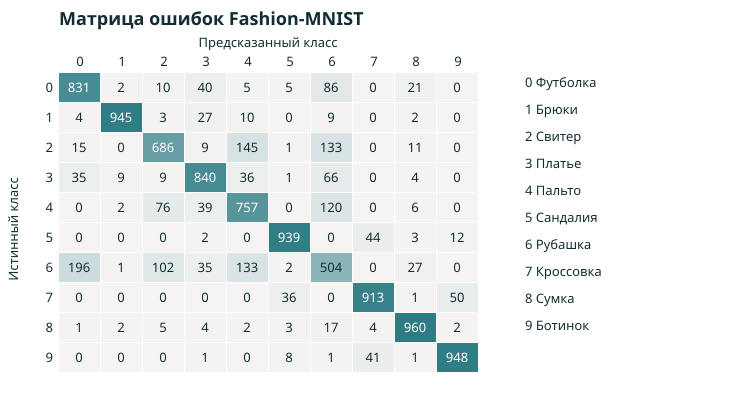

Наибольшая внедиагональная ячейка: Рубашка → Футболка 196


In [7]:
from IPython.display import SVG, display

accuracy, macro_f1, confusion = evaluate(model, test_loader, DEVICE)
assert confusion.shape == (10, 10) and confusion.sum().item() == 10000
print(f"test_accuracy={accuracy:.4f} test_macro_f1={macro_f1:.4f}")

class_names = (
    "Футболка", "Брюки", "Свитер", "Платье", "Пальто",
    "Сандалия", "Рубашка", "Кроссовка", "Сумка", "Ботинок",
)
marks = []
for i, row in enumerate(confusion.tolist()):
    marks.append(f'<text x="53" y="{92 + 30*i}" text-anchor="end">{i}</text>')
    marks.append(f'<text x="{80 + 42*i}" y="66" text-anchor="middle">{i}</text>')
    for j, count in enumerate(row):
        x, y = 59 + 42*j, 73 + 30*i
        strength = min(count / 1000, 1)
        green = int(244 - 125 * strength)
        blue = int(243 - 115 * strength)
        red = int(245 - 208 * strength)
        fill = f"rgb({red},{green},{blue})"
        text_color = "white" if strength > 0.65 else "#132e31"
        marks.append(f'<rect x="{x}" y="{y}" width="41" height="29" fill="{fill}"/>')
        marks.append(f'<text x="{x+20}" y="{y+19}" text-anchor="middle" '
                     f'fill="{text_color}">{count}</text>')
for i, name in enumerate(class_names):
    marks.append(f'<text x="525" y="{87 + 27*i}">{i}  {name}</text>')

svg = (
    '<svg xmlns="http://www.w3.org/2000/svg" width="730" height="410" '
    'viewBox="0 0 730 410" font-family="sans-serif" font-size="13" fill="#132e31" '
    'role="img" aria-label="Матрица ошибок на официальном тесте Fashion-MNIST">'
    '<rect width="730" height="410" fill="white"/>'
    '<text x="59" y="25" font-size="18" font-weight="bold">Матрица ошибок Fashion-MNIST</text>'
    '<text x="268" y="47" text-anchor="middle">Предсказанный класс</text>'
    '<text x="18" y="229" text-anchor="middle" transform="rotate(-90 18 229)">Истинный класс</text>'
    + "".join(marks)
    + "</svg>"
)
display(SVG(svg))
mistakes = confusion.clone()
mistakes.fill_diagonal_(0)
pair = mistakes.argmax().item()
print("Наибольшая внедиагональная ячейка:",
      f"{class_names[pair // 10]} → {class_names[pair % 10]}", mistakes.max().item())

## 6. Самостоятельная работа
**A.** Вручную вычислите первое окно при dilation=2 и угол карты при padding=1.
Сверьте полный результат с Python. Для одного слоя подсчитайте параметры.

**B.** Выполните пять эпох CNN2 и сохраните строки валидации, итоговые метрики и
матрицу ошибок. Разберите две наиболее заметные пары ошибок.

**C.** Сравните CNN2 и CNN3 по валидации при одинаковых разбиении, числе эпох и
батче. Посчитайте параметры, объясните пространственные формы и используйте тест
для итоговой оценки выбранной конфигурации.

Методическая основа — «Лабораторная работа 3.docx» и занятие С3. Данные —
[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist).